# Visual temporal DROZY

Sumber: Massoz et al., WACV 2016, DOI 10.1109/WACV.2016.7477715. Landmark dan timestamp asli; gambar database tidak ditampilkan.

In [1]:
from pathlib import Path
import os
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS'):
    os.environ.setdefault(key, '4')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
os.chdir(ROOT)
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from atc_fatigue.utils.runtime import load_config
config = load_config()
%matplotlib inline


In [2]:
windows = pd.read_parquet('data/interim/drozy/windows.parquet')
display(windows[['session_id', 'window_start_ms', 'ear_mean', 'blink_count', 'perclos', 'valid_coverage', 'target_value']].head())
print('Windows:', len(windows), 'Tests:', windows.session_id.nunique(), 'Subjects:', windows.subject_id.nunique())

,session_id,window_start_ms,ear_mean,blink_count,perclos,valid_coverage,target_value
0,1-1,23.0,0.429510,12.0,0.0,1.000000,3.0
1,1-1,60023.0,0.436223,15.0,0.0,0.989850,3.0
2,1-1,120023.0,0.453793,4.0,0.0,0.994717,3.0
3,1-1,180023.0,0.456470,6.0,0.0,0.981567,3.0
4,1-1,240023.0,0.443432,9.0,0.0,0.994500,3.0


Windows: 360 Tests: 36 Subjects: 14


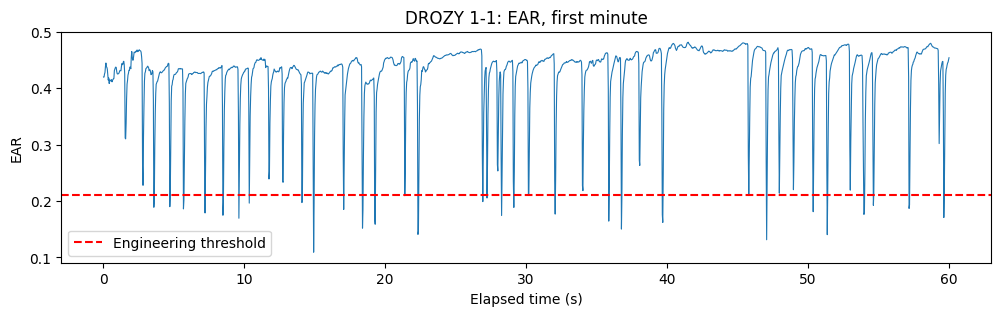

In [3]:
frames = pd.read_parquet('data/interim/drozy/1-1.frames.parquet')
selected = frames[frames.timestamp_ms < 60000]
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(selected.timestamp_ms/1000, selected.ear_mean, lw=0.8)
ax.axhline(config['visual']['ear_threshold'], color='red', ls='--', label='Engineering threshold')
ax.set(xlabel='Elapsed time (s)', ylabel='EAR', title='DROZY 1-1: EAR, first minute')
ax.legend(); plt.show()

In [4]:
from atc_fatigue.vision.eye_features import window_features
recomputed = window_features(frames.timestamp_ms, frames.ear_mean, config['visual'])
cached = windows[windows.session_id.eq('1-1')].reset_index(drop=True)
np.testing.assert_allclose(recomputed.perclos, cached.perclos, equal_nan=True)
display(recomputed[['blink_count', 'perclos', 'valid_coverage']])

,blink_count,perclos,valid_coverage
0,12,0.0,1.000000
1,15,0.0,0.989850
2,4,0.0,0.994717
3,6,0.0,0.981567
4,9,0.0,0.994500
5,14,0.0,0.994083
6,5,0.0,0.994367
7,11,0.0,0.989883
8,11,0.0,1.000000
9,4,0.0,0.993981


Threshold EAR 0,21 belum dikalibrasi. PERCLOS di sini adalah definisi operasional closure >=500 ms, berbobot durasi dan mengecualikan gap >150 ms. Label KSS per test bukan 360 label independen; regresi memakai agregat per test dan LOSO.